# Task 2 (deep) + Task 3 (session drift): Person C
**Question 2:** can an autoencoder trained only on one user's genuine typing flag impostors? (Task 2, deep models)
**Question 3:** does a user's typing drift across sessions, and does that hurt a detector trained on early sessions? (Task 3)

**Contract (frozen in `split.txt`):** per user, train on the 200 reps from sessions 1-4. Test = their 200 genuine reps from sessions 5-8 vs 250 impostor reps
(first 5 reps of session 1 for each of the other 50 users, the paper's protocol). Score convention: **higher = more genuine**, so score = -reconstruction error.
Results are appended to `../results.csv` as `(model, task, metric, value)` under tasks `task2_deep` and `task3_drift`.

**Run time (CPU):** about 6 min for Task 2, about 8 min for the drift experiment. Set `KD_FAST=1` for a 4-user smoke test (about 1 min).
**Run in VS Code:** keep the repo layout `data/` (CSV), `notebooks/` (this file), and put `ae_models.py` in the repo root next to `metrics.py` and `split.txt`. Open the notebook, pick your Python interpreter as the kernel (top right), then *Run All*. One-time install: `pip install torch numpy pandas scipy scikit-learn matplotlib seaborn ipykernel`. The `..` paths assume the notebook's own folder is the working directory (VS Code's default); if the first cell cannot find `metrics`, set the setting `jupyter.notebookFileRoot` to `${fileDirname}`.

Sections: 1 Setup · 2 Data and protocol · 3 Detectors · 4 Task 2 run · 5 Task 2 results · 6 Task 3: feature drift · 7 Task 3: drift experiment · 8 Export for the demo · 9 Summary

In [1]:
import os, sys, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
from scipy.stats import ks_2samp, wilcoxon
from sklearn.metrics import roc_curve
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
from metrics import append_result, load_split, eer   # shared contract file, never edited
import ae_models as A                                 # Person C's models: ROOT/ae_models.py

CFG = load_split(os.path.join(ROOT, "split.txt"))
SEED = CFG["SEED"]
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))

DATA = os.environ.get("KD_DATA", os.path.join(ROOT, "data", "DSL-StrongPasswordData.csv"))
RESULTS_PATH = os.environ.get("KD_RESULTS", os.path.join(ROOT, "results.csv"))
ART = os.environ.get("KD_ARTIFACTS", os.path.join(ROOT, "artifacts"))     # saved models for the demo
FIG = os.environ.get("KD_FIGURES", os.path.join(ROOT, "report", "figures"))
for d in (os.path.join(ART, "lstm_ae"), FIG):
    os.makedirs(d, exist_ok=True)
FAST = bool(int(os.environ.get("KD_FAST", "0")))                          # smoke test: 4 users only
TASKS = ("task2_deep", "task3_drift")

# Re-running must not duplicate rows: drop only THIS notebook's old rows.
if os.path.exists(RESULTS_PATH):
    _r = pd.read_csv(RESULTS_PATH)
    _r[~_r.task.isin(TASKS)].to_csv(RESULTS_PATH, index=False)

def log(model, task, metric, value):
    append_result(model, task, metric, value, path=RESULTS_PATH)

def savefig(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches="tight")

print("split:", {k: CFG[k] for k in ("TRAIN_SESSIONS", "TEST_SESSIONS", "IMPOSTOR_PER_USER", "IMPOSTOR_SESSION")},
      "| seed", SEED, "| FAST" if FAST else "")

split: {'TRAIN_SESSIONS': [1, 2, 3, 4], 'TEST_SESSIONS': [5, 6, 7, 8], 'IMPOSTOR_PER_USER': 5, 'IMPOSTOR_SESSION': 1} | seed 42 


## 2. Data and the frozen protocol
Rows are sorted by (subject, session, rep) so "first 200 reps" is unambiguous. The helpers below build, for any user, the three sets the protocol needs.
The asserts guard the contract: if `split.txt` or the data change, this fails loudly instead of silently producing non-comparable numbers.

In [2]:
df = pd.read_csv(DATA).sort_values(["subject", "sessionIndex", "rep"]).reset_index(drop=True)
feat_cols = [c for c in df.columns if c not in ("subject", "sessionIndex", "rep")]
assert len(feat_cols) == 31 and df[feat_cols].isna().sum().sum() == 0
assert df.subject.nunique() == 51 and (df.groupby("subject").size() == 400).all()
# ae_models.py hard-codes the H/DD/UD column layout; verify it against the real column names
assert A.H_IDX  == [i for i, c in enumerate(feat_cols) if c.startswith("H.")]
assert A.DD_IDX == [i for i, c in enumerate(feat_cols) if c.startswith("DD.")]
assert A.UD_IDX == [i for i, c in enumerate(feat_cols) if c.startswith("UD.")]

users = sorted(df.subject.unique())
by_user = {u: g for u, g in df.groupby("subject")}

def rows(u, sessions):                      # raw (n, 31) rows of user u from the given sessions
    g = by_user[u]
    return g[g.sessionIndex.isin(sessions)][feat_cols].values

def gen_train(u): return rows(u, CFG["TRAIN_SESSIONS"])
def gen_test(u):  return rows(u, CFG["TEST_SESSIONS"])
def impostors(u):
    out = []
    for v in users:
        if v == u: continue
        g = by_user[v]
        out.append(g[g.sessionIndex == CFG["IMPOSTOR_SESSION"]].head(CFG["IMPOSTOR_PER_USER"])[feat_cols].values)
    return np.vstack(out)

for u in users:
    assert gen_train(u).shape == (200, 31) and gen_test(u).shape == (200, 31) and impostors(u).shape == (250, 31)
users_eval = users[:4] if FAST else users
print(f"{len(users)} users | per user: 200 train, 200 genuine test, 250 impostors | evaluating {len(users_eval)} users")

51 users | per user: 200 train, 200 genuine test, 250 impostors | evaluating 51 users


## 3. Detectors
**Preprocessing:** a `StandardScaler` fit on the user's own 200 training reps only (never on test or other users). The 31 features are then reshaped into an
11-keystroke x [H, DD, UD] sequence (the last key has no DD/UD, so those two slots are padded and excluded from the loss).

**Models** (one small model *per user*, trained on genuine data only; the anomaly score is reconstruction error):
- `dense_ae`: 33 → 32 → 8 → 32 → 33 MLP autoencoder
- `lstm_ae`: LSTM encoder → 8-d bottleneck → LSTM decoder (the main model)
- `ref_manhattan_scaled`: the paper's scaled Manhattan detector, used as a **harness sanity check** (published mean EER 9.6%) and as the classical comparator in the drift study

**Training recipe (fixed up front, not tuned on sessions 5-8):** full-batch Adam, lr 3e-3, weight decay 1e-4, dropout 0.1. Epoch count is chosen on a validation slice
of the *training* sessions: stage 1 fits on sessions 1-3 and early-stops on session 4; stage 2 retrains on all 200 reps for the best epoch count.
The decision threshold for the demo is the 95th percentile of the stage-1 validation errors (training data only).
A small pilot on 7 users (train on sessions 1-3, validate genuine session 4 vs impostors) compared hidden sizes 8-64, bottleneck 4-12, weight decay and learning rate; all
configs were within noise (about 11-12% EER), so the cheapest sensible ones were kept. Raising the epoch cap from 300 to 800 gave no gain (median best epoch for the LSTM-AE is about 125).

In [3]:
MODELS = {
    "dense_ae": dict(arch="dense_ae", kwargs=dict(hidden=32, z=8)),
    "lstm_ae":  dict(arch="lstm_ae",  kwargs=dict(hidden=16, z=8)),
}
FIT = dict(epochs=300, lr=3e-3, wd=1e-4, patience=40)

def manhattan_scores(Xtr, evals):
    """Scaled Manhattan (Killourhy & Maxion): distance to the mean, each feature divided by its mean absolute deviation."""
    mu = Xtr.mean(0); mad = np.abs(Xtr - mu).mean(0)
    return [-(np.abs(E - mu) / mad).sum(1) for E in evals]

def fit_user_ae(name, Xtr, seed, epochs=None):
    """Fit one autoencoder on a user's raw (n, 31) training rows -> A.UserDetector.
    epochs=None : two-stage recipe above (early stop on the last 50 rows = session 4, then retrain on everything).
    epochs=int  : train exactly that many epochs, no validation (used in the drift study)."""
    cfg = MODELS[name]
    make = lambda: A.ARCHS[cfg["arch"]](**cfg["kwargs"])
    sc = StandardScaler().fit(Xtr)
    S = A.to_seq(sc.transform(Xtr))
    if epochs is None:
        m1, best_ep = A.fit_ae(make, S[:-50], S[-50:], seed=seed, **FIT)
        thr = float(np.percentile(A.recon_err(m1, S[-50:]), 95))
        best_ep = max(best_ep, 20)
        m, _ = A.fit_ae(make, S, None, epochs=best_ep, seed=seed, lr=FIT["lr"], wd=FIT["wd"])
    else:
        m, _ = A.fit_ae(make, S, None, epochs=epochs, seed=seed, lr=FIT["lr"], wd=FIT["wd"])
        best_ep, thr = epochs, float("nan")
    return A.UserDetector(cfg["arch"], cfg["kwargs"], m.state_dict(), sc.mean_, sc.scale_, thr, best_epoch=best_ep)

# quick smoke test on one user
u0 = users_eval[0]
_t = time.time(); d0 = fit_user_ae("lstm_ae", gen_train(u0), seed=SEED)
print(f"user {u0}: LSTM-AE EER {eer(d0.score(gen_test(u0)), d0.score(impostors(u0))):.3f}  "
      f"(best epoch {d0.best_epoch}, threshold {d0.threshold:.3f}, {time.time()-_t:.1f}s)")

user 2: LSTM-AE EER 0.244  (best epoch 299, threshold 1.326, 4.0s)


## 4. Task 2: run the protocol for every user
For each of the 51 users: train on their 200 genuine reps, score their 200 genuine test reps and the 250 impostor reps, compute the EER with the shared `metrics.eer`.
Trained LSTM-AE models are saved to `artifacts/lstm_ae/` for the Streamlit demo.

In [4]:
MODEL_NAMES = ("ref_manhattan_scaled", "dense_ae", "lstm_ae")
scores = {m: {} for m in MODEL_NAMES}      # scores[model][user] = (genuine_scores, impostor_scores)
info = {m: {} for m in ("dense_ae", "lstm_ae")}   # info[model][user] = (threshold, best_epoch)

t0 = time.time()
for k, u in enumerate(users_eval):
    Xtr, Xg, Xi = gen_train(u), gen_test(u), impostors(u)
    scores["ref_manhattan_scaled"][u] = tuple(manhattan_scores(Xtr, [Xg, Xi]))
    for name in ("dense_ae", "lstm_ae"):
        det = fit_user_ae(name, Xtr, seed=SEED + k)
        det.user = u.item() if hasattr(u, "item") else u
        scores[name][u] = (det.score(Xg), det.score(Xi))
        info[name][u] = (det.threshold, det.best_epoch)
        if name == "lstm_ae":
            det.save(os.path.join(ART, "lstm_ae", f"user_{u}.pt"))
    if (k + 1) % 5 == 0 or k + 1 == len(users_eval):
        print(f"  {k+1}/{len(users_eval)} users done  ({time.time()-t0:.0f}s)")

  5/51 users done  (19s)


  10/51 users done  (34s)


  15/51 users done  (49s)


  20/51 users done  (61s)


  25/51 users done  (78s)


  30/51 users done  (91s)


  35/51 users done  (105s)


  40/51 users done  (116s)


  45/51 users done  (129s)


  50/51 users done  (142s)


  51/51 users done  (145s)


## 5. Task 2 results
EER is computed **per user** (each user is its own detector), then summarised as mean ± std across users, which is how the paper reports it.
`ref_manhattan_scaled` should land near the published 9.6%; if it does, the protocol implementation matches the paper's.

In [5]:
PUBLISHED = {"Manhattan (scaled), paper": 0.096, "Mahalanobis NN, paper": 0.100, "One-class SVM, paper": 0.103}

recs = []
for m in MODEL_NAMES:
    for u, (g, i) in scores[m].items():
        r = dict(subject=u, model=m, eer=eer(g, i))
        if m in info:                                   # operating point at the training-derived threshold
            thr = info[m][u][0]
            r["frr"] = float(np.mean(-g > thr)); r["far"] = float(np.mean(-i <= thr)); r["best_epoch"] = info[m][u][1]
        recs.append(r)
per_user = pd.DataFrame(recs)
per_user.to_csv(os.path.join(ART, "task2_deep_per_user_eer.csv"), index=False)

summary = per_user.groupby("model").eer.agg(mean="mean", std="std", median="median").loc[list(MODEL_NAMES)]
print((summary * 100).round(2).rename(columns=lambda c: c + " EER %"))
print("\nPublished (paper):", {k: f"{v*100:.1f}%" for k, v in PUBLISHED.items()})

piv = per_user.pivot(index="subject", columns="model", values="eer")
if len(piv) >= 6:
    for m in ("dense_ae", "lstm_ae"):
        p = wilcoxon(piv[m], piv["ref_manhattan_scaled"]).pvalue
        print(f"Wilcoxon, {m} vs scaled Manhattan (paired per-user EER): p = {p:.2g}, "
              f"{m} better for {(piv[m] < piv['ref_manhattan_scaled']).sum()}/{len(piv)} users")

                      mean EER %  std EER %  median EER %
model                                                    
ref_manhattan_scaled        9.53       7.04          7.60
dense_ae                   10.04       6.27          9.35
lstm_ae                    11.51       6.52         10.60

Published (paper): {'Manhattan (scaled), paper': '9.6%', 'Mahalanobis NN, paper': '10.0%', 'One-class SVM, paper': '10.3%'}
Wilcoxon, dense_ae vs scaled Manhattan (paired per-user EER): p = 0.25, dense_ae better for 21/51 users
Wilcoxon, lstm_ae vs scaled Manhattan (paired per-user EER): p = 2.8e-05, lstm_ae better for 13/51 users


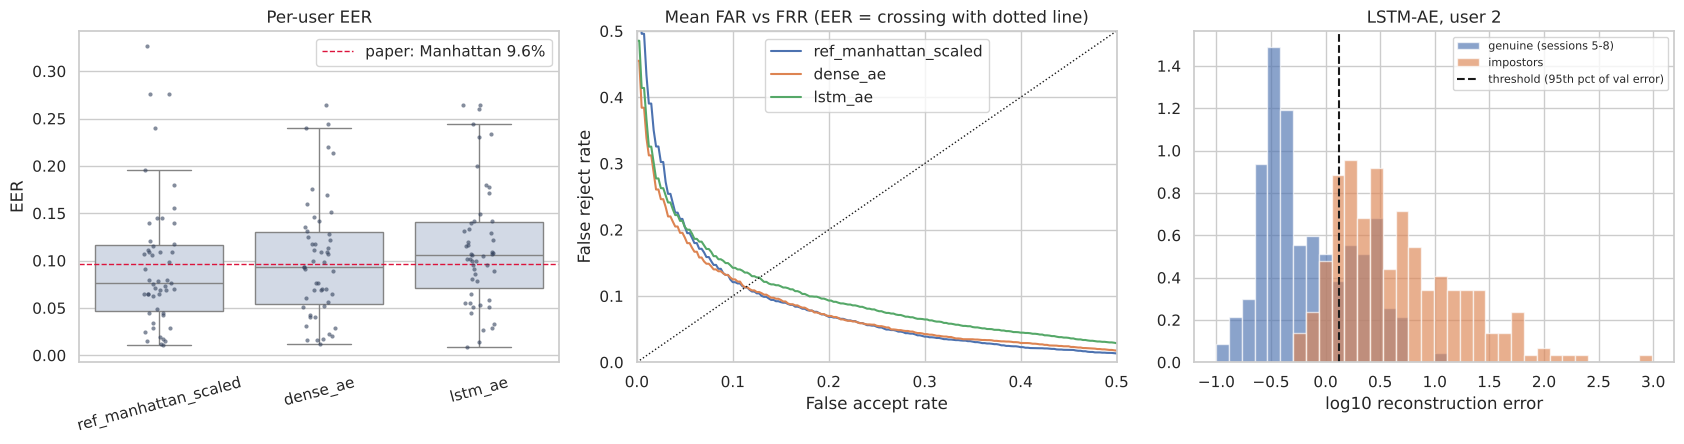

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) per-user EER distribution
order = list(MODEL_NAMES)
sns.boxplot(data=per_user, x="model", y="eer", order=order, ax=ax[0], showfliers=False, color="#cfd8e8")
sns.stripplot(data=per_user, x="model", y="eer", order=order, ax=ax[0], size=3, color="#33415c", alpha=.6)
ax[0].axhline(0.096, color="crimson", ls="--", lw=1, label="paper: Manhattan 9.6%"); ax[0].legend()
ax[0].set_title("Per-user EER"); ax[0].set_xlabel(""); ax[0].set_ylabel("EER"); ax[0].tick_params(axis="x", rotation=15)

# (b) mean FAR-vs-FRR curve; EER is where it crosses the diagonal
grid = np.linspace(0, 1, 401)
for m in MODEL_NAMES:
    frr = []
    for u, (g, i) in scores[m].items():
        y = np.r_[np.ones(len(g)), np.zeros(len(i))]
        fpr, tpr, _ = roc_curve(y, np.r_[g, i]); frr.append(1 - np.interp(grid, fpr, tpr))
    ax[1].plot(grid, np.mean(frr, 0), label=m)
ax[1].plot([0, 1], [0, 1], "k:", lw=1); ax[1].set_xlim(0, .5); ax[1].set_ylim(0, .5)
ax[1].set_xlabel("False accept rate"); ax[1].set_ylabel("False reject rate"); ax[1].set_title("Mean FAR vs FRR (EER = crossing with dotted line)"); ax[1].legend()

# (c) reconstruction error for one example user: genuine vs impostor, with the demo threshold
u = users_eval[0]; g, i = scores["lstm_ae"][u]
lg, li, lt = np.log10(-g), np.log10(-i), np.log10(info["lstm_ae"][u][0])      # errors are heavy-tailed -> log scale
bins = np.linspace(min(lg.min(), li.min()), max(lg.max(), li.max()), 35)
ax[2].hist(lg, bins=bins, alpha=.65, label="genuine (sessions 5-8)", density=True)
ax[2].hist(li, bins=bins, alpha=.65, label="impostors", density=True)
ax[2].axvline(lt, color="k", ls="--", label="threshold (95th pct of val error)")
ax[2].set_xlabel("log10 reconstruction error"); ax[2].set_title(f"LSTM-AE, user {u}"); ax[2].legend(fontsize=8)
plt.tight_layout(); savefig(fig, "task2_deep_results.png"); plt.show()

In [7]:
# Operating point at the training-derived threshold (what the demo will show), and logging to results.csv
op = per_user.dropna(subset=["far"]).groupby("model")[["far", "frr"]].mean()
print("Operating point at the validation-derived threshold (mean over users):")
print((op * 100).round(1).rename(columns=lambda c: c.upper() + " %"))

for m in MODEL_NAMES:
    s = summary.loc[m]
    log(m, "task2_deep", "eer_mean", s["mean"]); log(m, "task2_deep", "eer_std", s["std"]); log(m, "task2_deep", "eer_median", s["median"])
for m in op.index:
    log(m, "task2_deep", "far_at_threshold", op.loc[m, "far"]); log(m, "task2_deep", "frr_at_threshold", op.loc[m, "frr"])
print("\nlogged Task 2 rows to", RESULTS_PATH)

Operating point at the validation-derived threshold (mean over users):
          FAR %  FRR %
model                 
dense_ae   20.3    8.2
lstm_ae    24.9    8.5

logged Task 2 rows to /tmp/claude-0/-home-claude/4376eb88-561a-5c3c-b647-fe30ef8dc28d/scratchpad/Crun/results.csv


## 6. Task 3a: does typing actually change across sessions?
Before testing detectors, look at the raw features. For each user, features of each session are compared to that user's **own session 1** (z-scored by session 1's std).
Two views: the average absolute standardized shift per feature group, and total typing time relative to session 1 (below 1 = the user got faster).
A Kolmogorov-Smirnov test between sessions 1 and 8 counts how many (user, feature) pairs differ significantly.

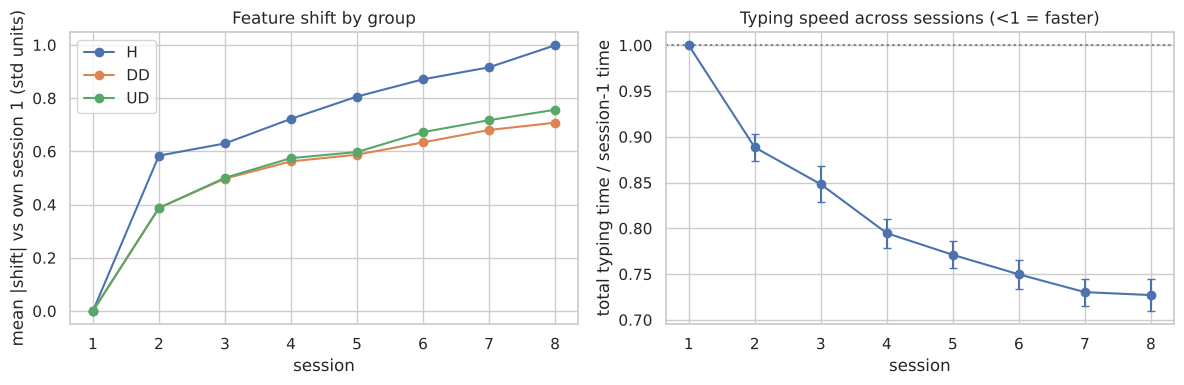

KS test session 1 vs 8: 1117/1581 (71%) of (user, feature) pairs differ at p < 0.01
typing time session 8 vs session 1: 0.727x on average


In [8]:
H_cols  = [c for c in feat_cols if c.startswith("H.")]
DD_cols = [c for c in feat_cols if c.startswith("DD.")]
UD_cols = [c for c in feat_cols if c.startswith("UD.")]
sess = sorted(df.sessionIndex.unique())

shift, speed = [], []
for u in users:
    g = by_user[u]; ref = g[g.sessionIndex == 1][feat_cols]; mu, sd = ref.mean(), ref.std()
    tt = lambda X: X[DD_cols].sum(1) + X["H.Return"]            # first press -> last release
    t1 = tt(ref).mean()
    for s in sess:
        gs = g[g.sessionIndex == s][feat_cols]; z = ((gs.mean() - mu) / sd).abs()
        shift.append(dict(subject=u, session=s, H=z[H_cols].mean(), DD=z[DD_cols].mean(), UD=z[UD_cols].mean()))
        speed.append(dict(subject=u, session=s, rel_time=tt(gs).mean() / t1))
shift, speed = pd.DataFrame(shift), pd.DataFrame(speed)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in ("H", "DD", "UD"):
    ax[0].plot(sess, shift.groupby("session")[c].mean(), marker="o", label=c)
ax[0].set_xlabel("session"); ax[0].set_ylabel("mean |shift| vs own session 1 (std units)"); ax[0].set_title("Feature shift by group"); ax[0].legend()
sp = speed.groupby("session").rel_time.agg(["mean", "sem"])
ax[1].errorbar(sess, sp["mean"], yerr=sp["sem"], marker="o", capsize=3)
ax[1].axhline(1, color="gray", ls=":"); ax[1].set_xlabel("session"); ax[1].set_ylabel("total typing time / session-1 time")
ax[1].set_title("Typing speed across sessions (<1 = faster)")
plt.tight_layout(); savefig(fig, "task3_feature_drift.png"); plt.show()

n_sig = n_all = 0
for u in users:
    g = by_user[u]
    a, b = g[g.sessionIndex == 1], g[g.sessionIndex == 8]
    for c in feat_cols:
        n_all += 1; n_sig += ks_2samp(a[c], b[c]).pvalue < 0.01
print(f"KS test session 1 vs 8: {n_sig}/{n_all} ({100*n_sig/n_all:.0f}%) of (user, feature) pairs differ at p < 0.01")
print(f"typing time session 8 vs session 1: {sp['mean'].iloc[-1]:.3f}x on average")

## 7. Task 3b: drift experiment
**Setup:** train each user's detector on **sessions 1-2 only** (100 reps), then measure EER separately on each later session 3-8 (50 genuine reps) against the same 250 frozen impostors.
If typing drifts, EER should rise as the gap from the training sessions grows.

- `static`: the model is never updated.
- `sliding`: the **mitigation**: before scoring session *s*, retrain on the two most recent sessions (*s-2*, *s-1*). For session 3 this equals `static`.

Both `ref_manhattan_scaled` and `lstm_ae` are compared, so we can ask which detector family is more drift-robust and how much of the loss a simple retraining policy recovers.

**Caveats for the report:** (1) EER from 50 genuine samples per session is coarse, so read trends rather than single points. (2) The frozen protocol takes all impostor reps from
session 1, so impostors are held fixed while the genuine user drifts. This isolates genuine drift but is not a full simulation of an attacker typing later, and it can flatter the `sliding` policy: a model retrained on a user's recent (faster, more practised) typing is automatically further from session-1 impostors, so `sliding` EER can fall *below* the session-3 level. Read `sliding` as 'drift is recoverable', not as an absolute accuracy gain. (3) Epoch count is fixed
at the median best epoch from Task 2 because there is no spare validation data in 100 reps.

In [9]:
DRIFT_TRAIN, DRIFT_EVAL = [1, 2], [3, 4, 5, 6, 7, 8]
EP_DRIFT = int(np.clip(np.median([v[1] for v in info["lstm_ae"].values()]), 30, 300))
RUN_SLIDING_LSTM = True        # set False to skip the ~5 min of extra training
print("epochs for drift runs:", EP_DRIFT)

drift = []
t0 = time.time()
for k, u in enumerate(users_eval):
    Xi = impostors(u)
    static_det = fit_user_ae("lstm_ae", rows(u, DRIFT_TRAIN), seed=SEED + k, epochs=EP_DRIFT)
    for s in DRIFT_EVAL:
        Xg = rows(u, [s])
        for mode in ("static", "sliding"):
            tr_sessions = DRIFT_TRAIN if (mode == "static" or s == 3) else [s - 2, s - 1]
            Xtr = rows(u, tr_sessions)
            g, i = manhattan_scores(Xtr, [Xg, Xi])
            drift.append(dict(subject=u, session=s, mode=mode, model="ref_manhattan_scaled", eer=eer(g, i)))
            if mode == "static" or s == 3:
                det = static_det
            elif RUN_SLIDING_LSTM:
                det = fit_user_ae("lstm_ae", Xtr, seed=SEED + k, epochs=EP_DRIFT)
            else:
                continue
            drift.append(dict(subject=u, session=s, mode=mode, model="lstm_ae", eer=eer(det.score(Xg), det.score(Xi))))
    if (k + 1) % 5 == 0 or k + 1 == len(users_eval):
        print(f"  {k+1}/{len(users_eval)} users done  ({time.time()-t0:.0f}s)")
drift = pd.DataFrame(drift)
drift.to_csv(os.path.join(ART, "task3_drift_per_user_eer.csv"), index=False)

epochs for drift runs: 168


  5/51 users done  (18s)


  10/51 users done  (36s)


  15/51 users done  (53s)


  20/51 users done  (72s)


  25/51 users done  (91s)


... (2 outputs left out)

  40/51 users done  (146s)


  45/51 users done  (165s)


  50/51 users done  (183s)


  51/51 users done  (186s)


session                          3     4     5     6     7     8
model                mode                                       
lstm_ae              sliding  12.5  10.9  10.3   9.4   8.9   9.4
                     static   12.5  12.9  13.0  12.4  13.4  13.6
ref_manhattan_scaled sliding   9.3   7.7   7.3   6.3   6.7   6.5
                     static    9.3   9.6  10.4  10.8  12.3  13.1


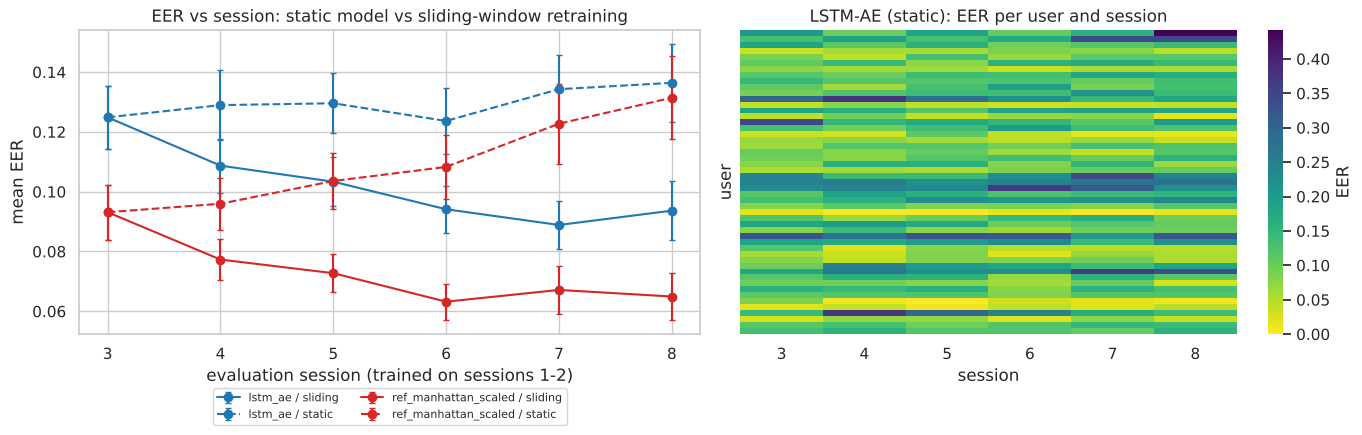

lstm_ae                sliding  EER slope: -0.64 pts/session | session 3 -> 8: 12.5% -> 9.4%
lstm_ae                static   EER slope: +0.19 pts/session | session 3 -> 8: 12.5% -> 13.6%
ref_manhattan_scaled   sliding  EER slope: -0.52 pts/session | session 3 -> 8: 9.3% -> 6.5%
ref_manhattan_scaled   static   EER slope: +0.79 pts/session | session 3 -> 8: 9.3% -> 13.1%


In [10]:
curve = drift.groupby(["model", "mode", "session"]).eer.agg(["mean", "sem"]).reset_index()
print((curve.pivot_table(index=["model", "mode"], columns="session", values="mean") * 100).round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
styles = {("ref_manhattan_scaled", "static"): ("tab:red", "--"), ("ref_manhattan_scaled", "sliding"): ("tab:red", "-"),
          ("lstm_ae", "static"): ("tab:blue", "--"), ("lstm_ae", "sliding"): ("tab:blue", "-")}
for (m, mode), d in curve.groupby(["model", "mode"]):
    col, ls = styles[(m, mode)]
    ax[0].errorbar(d.session, d["mean"], yerr=d["sem"], color=col, ls=ls, marker="o", capsize=2, label=f"{m} / {mode}")
ax[0].set_xlabel("evaluation session (trained on sessions 1-2)"); ax[0].set_ylabel("mean EER"); ax[0].set_title("EER vs session: static model vs sliding-window retraining")
ax[0].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)

hm = drift[(drift.model == "lstm_ae") & (drift["mode"] == "static")].pivot(index="subject", columns="session", values="eer")
sns.heatmap(hm, ax=ax[1], cmap="viridis_r", cbar_kws={"label": "EER"}, yticklabels=(len(hm) <= 12))
ax[1].set_title("LSTM-AE (static): EER per user and session"); ax[1].set_ylabel("user")
plt.tight_layout(); savefig(fig, "task3_drift_curves.png"); plt.show()

# trend: linear slope of the mean static EER over sessions 3-8 (EER points per session)
for (m, mode), d in curve.groupby(["model", "mode"]):
    slope = np.polyfit(d.session, d["mean"], 1)[0]
    print(f"{m:22s} {mode:8s} EER slope: {slope*100:+.2f} pts/session | session 3 -> 8: {d['mean'].iloc[0]*100:.1f}% -> {d['mean'].iloc[-1]*100:.1f}%")
    log(f"{m}_{mode}", "task3_drift", "eer_slope_per_session", slope)
    for _, r in d.iterrows():
        log(f"{m}_{mode}", "task3_drift", f"eer_mean_s{int(r.session)}", r["mean"])

## 8. Export check for the Streamlit tab
The demo tab does not retrain anything: it loads `artifacts/lstm_ae/user_<id>.pt` with `A.UserDetector.load`, which restores the scaler, network and threshold.
This cell proves the round-trip: a reloaded detector must give identical scores to the in-memory run, and shows the accept/reject decision on one genuine and one impostor sample.

In [11]:
u = users_eval[0]
det = A.UserDetector.load(os.path.join(ART, "lstm_ae", f"user_{u}.pt"))
Xg, Xi = gen_test(u), impostors(u)
g_ref, i_ref = scores["lstm_ae"][u]
assert np.allclose(det.score(Xg), g_ref, atol=1e-5) and np.allclose(det.score(Xi), i_ref, atol=1e-5)
print(f"reloaded detector for {u} matches the in-memory run. threshold = {det.threshold:.3f}")
print("genuine sample  -> error %.3f, accepted: %s" % (det.error(Xg[0])[0], bool(det.is_genuine(Xg[0])[0])))
print("impostor sample -> error %.3f, accepted: %s" % (det.error(Xi[0])[0], bool(det.is_genuine(Xi[0])[0])))
print("saved models:", len([f for f in os.listdir(os.path.join(ART, 'lstm_ae')) if f.endswith('.pt')]))

reloaded detector for 2 matches the in-memory run. threshold = 1.326
genuine sample  -> error 0.383, accepted: True
impostor sample -> error 2.213, accepted: False
saved models: 51


## 9. Summary

In [12]:
res = pd.read_csv(RESULTS_PATH)
mine = res[res.task.isin(TASKS)]
print(mine[mine.task == "task2_deep"].pivot_table(index="model", columns="metric", values="value").round(4))
print()
print(mine[mine.task == "task3_drift"].pivot_table(index="model", columns="metric", values="value").round(4)[
    [f"eer_mean_s{s}" for s in DRIFT_EVAL] + ["eer_slope_per_session"]])

metric                eer_mean  eer_median  eer_std  far_at_threshold  \
model                                                                   
dense_ae                0.1004      0.0935   0.0627            0.2025   
lstm_ae                 0.1151      0.1060   0.0652            0.2486   
ref_manhattan_scaled    0.0953      0.0760   0.0704               NaN   

metric                frr_at_threshold  
model                                   
dense_ae                        0.0819  
lstm_ae                         0.0853  
ref_manhattan_scaled               NaN  

metric                        eer_mean_s3  eer_mean_s4  eer_mean_s5  \
model                                                                 
lstm_ae_sliding                    0.1249       0.1087       0.1033   
lstm_ae_static                     0.1249       0.1289       0.1296   
ref_manhattan_scaled_sliding       0.0931       0.0773       0.0727   
ref_manhattan_scaled_static        0.0931       0.0960       0.1036   

m

**Reading the results (fill in after the full run):**
- *Task 2:* does the LSTM-AE beat the dense AE? How does it compare to scaled Manhattan (9.6% in the paper, reproduced here as the harness check) and to the other published numbers? Why does a well-regularised autoencoder avoid the failure of the paper's standard NN (82.8% EER)?
- *Task 3:* how much does EER rise between session 3 and session 8? Is the LSTM-AE or Manhattan more drift-robust? How much of the loss does sliding-window retraining recover? Link to Section 6: people type faster over time.
- *Limitations:* one fixed 10-character password, 51 users, 50 genuine samples per drift point, impostors from session 1 only.
- *Stretch (if time allows):* Siamese network for few-shot verification, which would sit on top of the same `split.txt`/`metrics.py` contract.